In [ ]:
#Laboratorio 18

In [1]:
import pandas as pd
import numpy as np

In [2]:
from ucimlrepo import fetch_ucirepo

In [3]:
# fetch dataset
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

In [4]:
# data (as pandas dataframes)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

In [5]:
# variable information
print(breast_cancer_wisconsin_diagnostic.variables)

                  name     role         type demographic description units  \
0                   ID       ID  Categorical        None        None  None   
1            Diagnosis   Target  Categorical        None        None  None   
2              radius1  Feature   Continuous        None        None  None   
3             texture1  Feature   Continuous        None        None  None   
4           perimeter1  Feature   Continuous        None        None  None   
5                area1  Feature   Continuous        None        None  None   
6          smoothness1  Feature   Continuous        None        None  None   
7         compactness1  Feature   Continuous        None        None  None   
8           concavity1  Feature   Continuous        None        None  None   
9      concave_points1  Feature   Continuous        None        None  None   
10           symmetry1  Feature   Continuous        None        None  None   
11  fractal_dimension1  Feature   Continuous        None        

In [6]:
dfCancer = pd.concat([X,y], axis=1)

In [7]:
dfCancer.head(2)

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M


In [10]:
dfCancer.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavity2         

In [11]:
# Identificar las variables numericas y categoricas
dfCancer.describe()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [13]:
varibles_categoricas = dfCancer.select_dtypes(
    include = ["object","str","bool"])
print("Variables categoricas")
print(varibles_categoricas.columns.tolist())

Variables categoricas
['Diagnosis']


In [12]:
# Verificar si hay valores nulos
print ("Valores nulos por columnas: ")
print (dfCancer.isnull().sum())

Valores nulos por columnas: 
radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
Diagnosis             0
dtype: int64


In [14]:
dfCancer["Diagnosis"].sample()

383    B
Name: Diagnosis, dtype: str

In [15]:
# Selección de las variables predictoras y variable objetivo
# Variables predictoras
X = dfCancer.drop(columns=["Diagnosis"])
# Variable objetivo
y = dfCancer['Diagnosis']

In [17]:
#Identificar las clases presentes en la variable objetivo
for columna in varibles_categoricas.columns:
    print(f"Variable:{columna}")
    print("Categoricas: ",dfCancer[columna].unique())

Variable:Diagnosis
Categoricas:  <StringArray>
['M', 'B']
Length: 2, dtype: str


In [18]:
variableObjetivo = dfCancer.columns[-1]

In [20]:
# c)¿Cuantos ejemplos hay en cada clase?
print(dfCancer[variableObjetivo].value_counts())

Diagnosis
B    357
M    212
Name: count, dtype: int64


In [ ]:
# d) ¿La distribución de clases está balanceada?
# Respuesta NO

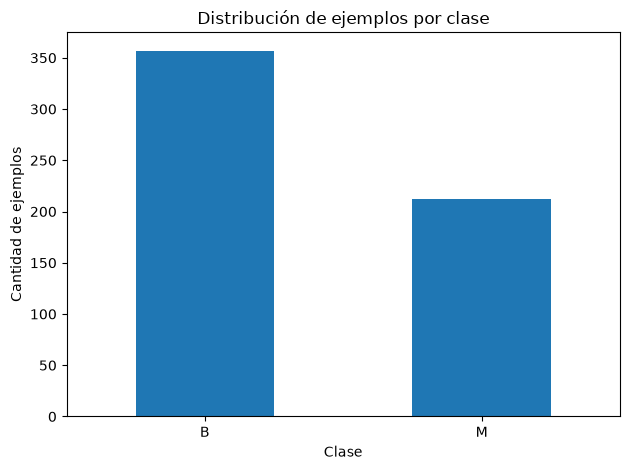

In [21]:
import matplotlib.pyplot as plt
dfCancer[variableObjetivo].value_counts().plot(kind="bar")
plt.title("Distribución de ejemplos por clase")
plt.xlabel("Clase")
plt.ylabel("Cantidad de ejemplos")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# e) ¿Que consecuencias prodria tener un desbalance de clase al evaluar el modelo?
# Respuesta El modelo puede darle preferencia a la clase mayoritaria

In [22]:
print("Dimensiones de X: ", X.shape)
print("Dimensiones de y: ",y.shape)

Dimensiones de X:  (569, 30)
Dimensiones de y:  (569,)


In [23]:
#Verificae que no existan valores nulos
X.isnull().sum()

radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
dtype: int64

In [24]:
# Dividir los datos
from sklearn.model_selection import train_test_split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 21,
    stratify= y
)

In [26]:
print ("Datos originales: ", X.shape[0])
print ("----------------------")
print ("Conjunto de entrenamiento:")
print ("X_train: ", X_train.shape)
print ("y_train: ", y_train.shape)
print ("------------------------")
print ("Conjunto de prueba:")
print ("X_test: ", X_test.shape)
print ("y_test: ", y_test.shape)

Datos originales:  569
----------------------
Conjunto de entrenamiento:
X_train:  (455, 30)
y_train:  (455,)
------------------------
Conjunto de prueba:
X_test:  (114, 30)
y_test:  (114,)


In [27]:
# Entrenar el arbol de decision
from sklearn.tree import DecisionTreeClassifier

In [28]:
modelo = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3, 
    min_samples_split=10,
    min_samples_leaf=5
)

In [29]:
modelo.fit(X_train, y_train)
print("El arbol de decision se entreno correctamente")

El arbol de decision se entreno correctamente


In [31]:
print("Profundidad real del arbol: ", modelo.get_depth())
print("Número de hojas: ", modelo.get_n_leaves())
print("Número de variables predictoras: ", modelo.n_features_in_)

Profundidad real del arbol:  3
Número de hojas:  8
Número de variables predictoras:  30


In [33]:
print("Clases aprendidad por el modelo:")
print(modelo.classes_)

Clases aprendidad por el modelo:
['B' 'M']
